
# Machine Learning Model Building for Startup Funding Analysis

## 1. Introduction

Machine learning is a branch of artificial intelligence that enables computers to learn patterns from data and make predictions.

In this notebook, we build regression models to predict startup funding amounts using relevant features from the feature-engineered dataset.

### Objectives

- Load the feature-engineered dataset.
- Select relevant input features and target variable.
- Prepare categorical and numerical data for modeling.
- Split the dataset into training and testing sets.
- Build and compare multiple regression models.
- Evaluate model performance using appropriate metrics.



## 2. Import Required Libraries

We import the libraries required for data handling, preprocessing, machine learning model building and model evaluation.


In [39]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!



## 3. Load the Feature-Engineered Dataset

We load the dataset created during the feature engineering stage.

This dataset contains the original cleaned information along with the newly created features, which will be used to train our machine learning models.


In [40]:

file_path = "../data/processed/startup_funding_feature_engineered.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (3044, 26)


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks,...,SubVertical_Cleaned,Investment_Type_Cleaned,Investors_Cleaned,Remarks_Cleaned,Is_Outlier,Month,City_Grouped,Industry_Grouped,Investment_Type_Grouped,Year
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN,...,E-Learning,Private Equity,Tiger Global Management,NaN,True,1,Bengaluru,E-Tech,Private Equity,2020
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN,...,App Based Shuttle Service,Series C,Susquehanna Growth Equity,NaN,False,1,Gurugram,Transportation,Other,2020
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN,...,Retailer Of Baby And Toddler Products,Series B,Sequoia Capital India,NaN,False,1,Bengaluru,Ecommerce,Series B,2020
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN,...,Online Investment,Pre-Series A,Vinod Khatumal,NaN,False,1,New Delhi,Fintech,Other,2020
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN,...,Embroiled Clothes For Women,Seed Round,Sprout Venture Partners,NaN,False,1,Mumbai,Fashion And Apparel,Other,2020


In [41]:
print("Number of industry categories:")
print(df["Industry_Grouped"].nunique())

print("\nIndustry category counts:")
display(df["Industry_Grouped"].value_counts())

print("\nNumber of missing industry values:")
print(df["Industry_Grouped"].isna().sum())

Number of industry categories:
793

Industry category counts:


Industry_Grouped
Consumer Internet                 942
Technology                        478
Ecommerce                         299
Unknown                           171
Healthcare                         71
                                 ... 
Mobile Food Ordering App            1
Financial Markets Software          1
Hiring Analytics Platform           1
Online Travel Marketplace           1
Restaurant Management Platform      1
Name: count, Length: 793, dtype: int64


Number of missing industry values:
0


In [42]:
industry_counts = df[
    df["Industry_Grouped"] != "Unknown"
]["Industry_Grouped"].value_counts()

print("Total known industry categories:", len(industry_counts))

print("\nCategories with at least 5 records:",
      (industry_counts >= 5).sum())

print("Categories with at least 10 records:",
      (industry_counts >= 10).sum())

print("Categories with at least 20 records:",
      (industry_counts >= 20).sum())

print("\nRecords available in each selection:")

print("At least 5 records:", industry_counts[industry_counts >= 5].sum())
print("At least 10 records:", industry_counts[industry_counts >= 10].sum())
print("At least 20 records:", industry_counts[industry_counts >= 20].sum())

Total known industry categories: 792

Categories with at least 5 records: 17
Categories with at least 10 records: 11
Categories with at least 20 records: 9

Records available in each selection:
At least 5 records: 2023
At least 10 records: 1990
At least 20 records: 1963


In [ ]:

selected_industries = industry_counts[
    (industry_counts >= 10) &
    (industry_counts.index != "Unknown")
].index


model_df = df[
    df["Industry_Grouped"].isin(selected_industries)
].copy()

print("Model dataset shape:", model_df.shape)

print("\nNumber of industries:",
      model_df["Industry_Grouped"].nunique())

print("\nIndustry distribution:")
display(model_df["Industry_Grouped"].value_counts())

Model dataset shape: (1990, 26)

Number of industries: 11

Industry distribution:


Industry_Grouped
Consumer Internet    942
Technology           478
Ecommerce            299
Healthcare            71
Finance               62
Food & Beverage       35
Logistics             32
Education             24
EdTech                20
Fintech               16
IT                    11
Name: count, dtype: int64


## 4. Feature Selection

Feature selection involves identifying relevant input features and the target variable for machine learning.

In this project, we aim to predict the industry sector of a startup using its available information.

### Input Features (X)
- Year
- Month
- City_Grouped
- Investment_Type_Grouped

### Target Variable (y)
- Industry_Grouped

The model learns patterns from historical startup records and predicts the likely industry sector based on the selected input features.


### Preparing Input Features and Target Variable

The selected input features are Year, Month, City_Grouped and Investment_Type_Grouped.

The target variable is Industry_Grouped, which represents the startup's industry sector.

Records with an Unknown industry are excluded because they do not contain reliable target information. The Other category is retained to represent less frequent industries.

In [ ]:

selected_features = [
    "Year",
    "Month",
    "City_Grouped",
    "Investment_Type_Grouped",
    "Amount_Cleaned",
    "SubVertical_Cleaned"
]

X = model_df[selected_features]


y = model_df["Industry_Grouped"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nSelected input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

Input features shape: (1990, 6)
Target variable shape: (1990,)

Selected input features:


,Year,Month,City_Grouped,Investment_Type_Grouped,Amount_Cleaned,SubVertical_Cleaned
2,2020,1,Bengaluru,Series B,18358860.0,Retailer Of Baby And Toddler Products
3,2020,1,New Delhi,Other,3000000.0,Online Investment
5,2020,1,Chennai,Series A,9000000.0,"Open-Market, Freight Management Platform"
7,2019,12,Pune,Series A,6000000.0,Agritech
8,2019,12,Gurugram,Other,70000000.0,Automobile



Target variable:


2     Ecommerce
3       Fintech
5     Logistics
7    Technology
8     Ecommerce
Name: Industry_Grouped, dtype: object

In [45]:
print("Available columns in model_df:")
print(model_df.columns.tolist())

Available columns in model_df:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks', 'Date_Converted', 'Date_Cleaned', 'Amount_Approximate', 'Amount_Cleaned', 'City_Cleaned', 'Industry_Cleaned', 'SubVertical_Cleaned', 'Investment_Type_Cleaned', 'Investors_Cleaned', 'Remarks_Cleaned', 'Is_Outlier', 'Month', 'City_Grouped', 'Industry_Grouped', 'Investment_Type_Grouped', 'Year']


In [46]:
print("Does Industry_Grouped contain Other?")
print((model_df["Industry_Grouped"] == "Other").any())

print("\nIndustry categories:")
display(model_df["Industry_Grouped"].value_counts())

Does Industry_Grouped contain Other?
False

Industry categories:


Industry_Grouped
Consumer Internet    942
Technology           478
Ecommerce            299
Healthcare            71
Finance               62
Food & Beverage       35
Logistics             32
Education             24
EdTech                20
Fintech               16
IT                    11
Name: count, dtype: int64

## 5. Splitting Training and Testing Data

The dataset is divided into training and testing sets.

- Training data (80%): Used by the model to learn patterns.
- Testing data (20%): Used to evaluate how well the model predicts unseen records.

Stratified sampling is used to maintain the proportion of each industry category in both sets.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (1592, 6)
Testing input shape: (398, 6)

Training target shape: (1592,)
Testing target shape: (398,)


## 6. Data Preprocessing

Numerical features are prepared using median imputation and scaling.

Funding amounts are additionally transformed using a logarithmic transformation to reduce skewness.

Categorical features are converted into numerical representations using One-Hot Encoding.

In [ ]:
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

numerical_features = ["Year", "Month"]
amount_feature = ["Amount_Cleaned"]

categorical_features = [
    "City_Grouped",
    "Investment_Type_Grouped",
    "SubVertical_Cleaned"
]


numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


amount_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])


categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("amount", amount_transformer, amount_feature),
    ("cat", categorical_transformer, categorical_features)
])

print("Updated preprocessing setup completed!")

Updated preprocessing setup completed!


## 7. Model 1: Logistic Regression

Logistic Regression is a classification algorithm used to predict the category or class of a given input.

In this project, it learns patterns from startup details and predicts the likely industry sector.

A preprocessing pipeline is used to transform the input data before training the model.

In [ ]:
from sklearn.linear_model import LogisticRegression


logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])


logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## 8. Predictions Using Logistic Regression

After training the model, we use the testing data to predict the industry sectors of startups.

The predicted values are compared with the actual industry sectors to evaluate model performance.

In [ ]:

y_pred_logistic = logistic_model.predict(X_test)


comparison = pd.DataFrame({
    "Actual Industry": y_test.values,
    "Predicted Industry": y_pred_logistic
})

display(comparison.head(10))

,Actual Industry,Predicted Industry
0,Consumer Internet,Consumer Internet
1,Consumer Internet,Technology
2,Logistics,Consumer Internet
3,Ecommerce,Finance
4,Technology,Consumer Internet
5,Healthcare,Consumer Internet
6,Consumer Internet,Consumer Internet
7,Consumer Internet,Ecommerce
8,Ecommerce,Ecommerce
9,Logistics,Technology


## 9. Evaluation of Logistic Regression

The performance of the Logistic Regression model is evaluated using the following classification metrics:

- Accuracy: Measures the overall percentage of correct predictions.
- Precision: Measures how many predicted records for a category are actually correct.
- Recall: Measures how many actual records of a category are correctly identified.
- F1-score: Provides a balance between precision and recall.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)


logistic_accuracy = accuracy_score(y_test, y_pred_logistic)


logistic_macro_f1 = f1_score(
    y_test, y_pred_logistic, average="macro"
)

logistic_weighted_f1 = f1_score(
    y_test, y_pred_logistic, average="weighted"
)

print("Logistic Regression Accuracy:", logistic_accuracy)
print("Macro F1-score:", logistic_macro_f1)
print("Weighted F1-score:", logistic_weighted_f1)


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

Logistic Regression Accuracy: 0.3969849246231156
Macro F1-score: 0.16937434207351726
Weighted F1-score: 0.42755704950503187

Classification Report:
                   precision    recall  f1-score   support

Consumer Internet       0.68      0.49      0.57       188
        Ecommerce       0.39      0.37      0.38        60
           EdTech       0.00      0.00      0.00         4
        Education       0.00      0.00      0.00         5
          Finance       0.14      0.42      0.21        12
          Fintech       0.00      0.00      0.00         3
  Food & Beverage       0.20      0.29      0.24         7
       Healthcare       0.08      0.14      0.11        14
               IT       0.00      0.00      0.00         2
        Logistics       0.00      0.00      0.00         7
       Technology       0.36      0.36      0.36        96

         accuracy                           0.40       398
        macro avg       0.17      0.19      0.17       398
     weighted avg       

### 9.1 Confusion Matrix for Logistic Regression

A confusion matrix compares the actual industry categories with the categories predicted by the model.

It helps identify correct predictions and the industries that are frequently misclassified.

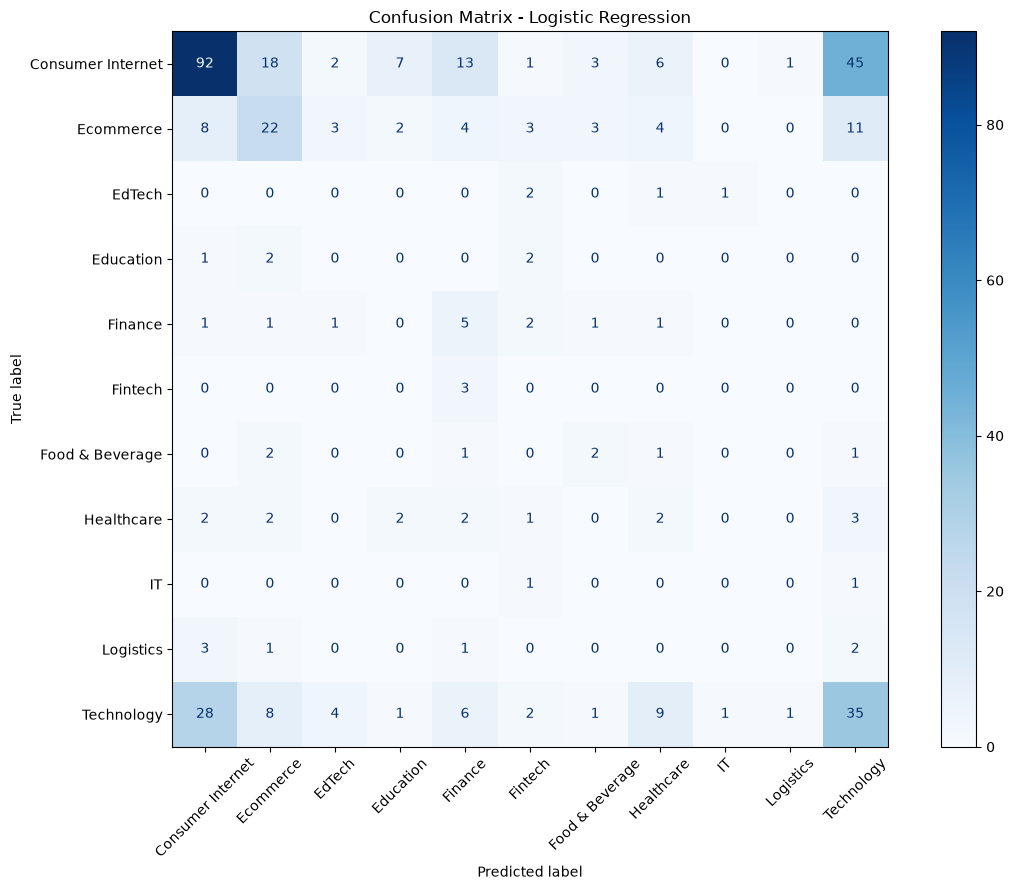

[[92 18  2  7 13  1  3  6  0  1 45]
 [ 8 22  3  2  4  3  3  4  0  0 11]
 [ 0  0  0  0  0  2  0  1  1  0  0]
 [ 1  2  0  0  0  2  0  0  0  0  0]
 [ 1  1  1  0  5  2  1  1  0  0  0]
 [ 0  0  0  0  3  0  0  0  0  0  0]
 [ 0  2  0  0  1  0  2  1  0  0  1]
 [ 2  2  0  2  2  1  0  2  0  0  3]
 [ 0  0  0  0  0  1  0  0  0  0  1]
 [ 3  1  0  0  1  0  0  0  0  0  2]
 [28  8  4  1  6  2  1  9  1  1 35]]

Industry labels:
['Consumer Internet' 'Ecommerce' 'EdTech' 'Education' 'Finance' 'Fintech'
 'Food & Beverage' 'Healthcare' 'IT' 'Logistics' 'Technology']


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=logistic_model.classes_
)

fig, ax = plt.subplots(figsize=(12, 9))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()
print(cm_logistic)
print("\nIndustry labels:")
print(logistic_model.classes_)

## 10. Model 2: Decision Tree Classifier

A Decision Tree is a machine learning algorithm that makes predictions by following a sequence of decision rules.

It divides the data based on feature values and predicts the industry sector based on the learned patterns.

In this project, the Decision Tree model is used to classify startups into their respective industry sectors.

In [ ]:
from sklearn.tree import DecisionTreeClassifier


decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])


decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


### 10.1 Predictions Using Decision Tree

The trained Decision Tree model is used to predict the industry sectors of the testing records.

The predicted industry categories are compared with the actual categories to understand the model's predictions.

In [ ]:

y_pred_tree = decision_tree_model.predict(X_test)


tree_comparison = pd.DataFrame({
    "Actual Industry": y_test.values,
    "Predicted Industry": y_pred_tree
})

display(tree_comparison.head(10))

,Actual Industry,Predicted Industry
0,Consumer Internet,Consumer Internet
1,Consumer Internet,Consumer Internet
2,Logistics,Consumer Internet
3,Ecommerce,Finance
4,Technology,Ecommerce
5,Healthcare,Technology
6,Consumer Internet,Consumer Internet
7,Consumer Internet,Consumer Internet
8,Ecommerce,Consumer Internet
9,Logistics,Consumer Internet


### 10.2 Evaluation of Decision Tree

The Decision Tree model is evaluated using accuracy, precision, recall and F1-score.

These metrics help measure how effectively the model predicts the industry sectors.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)


tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_macro_f1 = f1_score(
    y_test, y_pred_tree, average="macro"
)

tree_weighted_f1 = f1_score(
    y_test, y_pred_tree, average="weighted"
)

print("Decision Tree Accuracy:", tree_accuracy)
print("Macro F1-score:", tree_macro_f1)
print("Weighted F1-score:", tree_weighted_f1)


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    zero_division=0
))

Decision Tree Accuracy: 0.3492462311557789
Macro F1-score: 0.1361965942313408
Weighted F1-score: 0.34590760914694074

Classification Report:
                   precision    recall  f1-score   support

Consumer Internet       0.57      0.60      0.58       188
        Ecommerce       0.14      0.10      0.12        60
           EdTech       0.00      0.00      0.00         4
        Education       0.00      0.00      0.00         5
          Finance       0.14      0.25      0.18        12
          Fintech       0.12      0.33      0.18         3
  Food & Beverage       0.00      0.00      0.00         7
       Healthcare       0.08      0.07      0.07        14
               IT       0.11      0.50      0.18         2
        Logistics       0.00      0.00      0.00         7
       Technology       0.22      0.16      0.18        96

         accuracy                           0.35       398
        macro avg       0.13      0.18      0.14       398
     weighted avg       0.35   

### 10.3 Confusion Matrix for Decision Tree

The confusion matrix compares the actual industry categories with the categories predicted by the Decision Tree model.

It helps identify correct predictions and misclassifications for each industry.

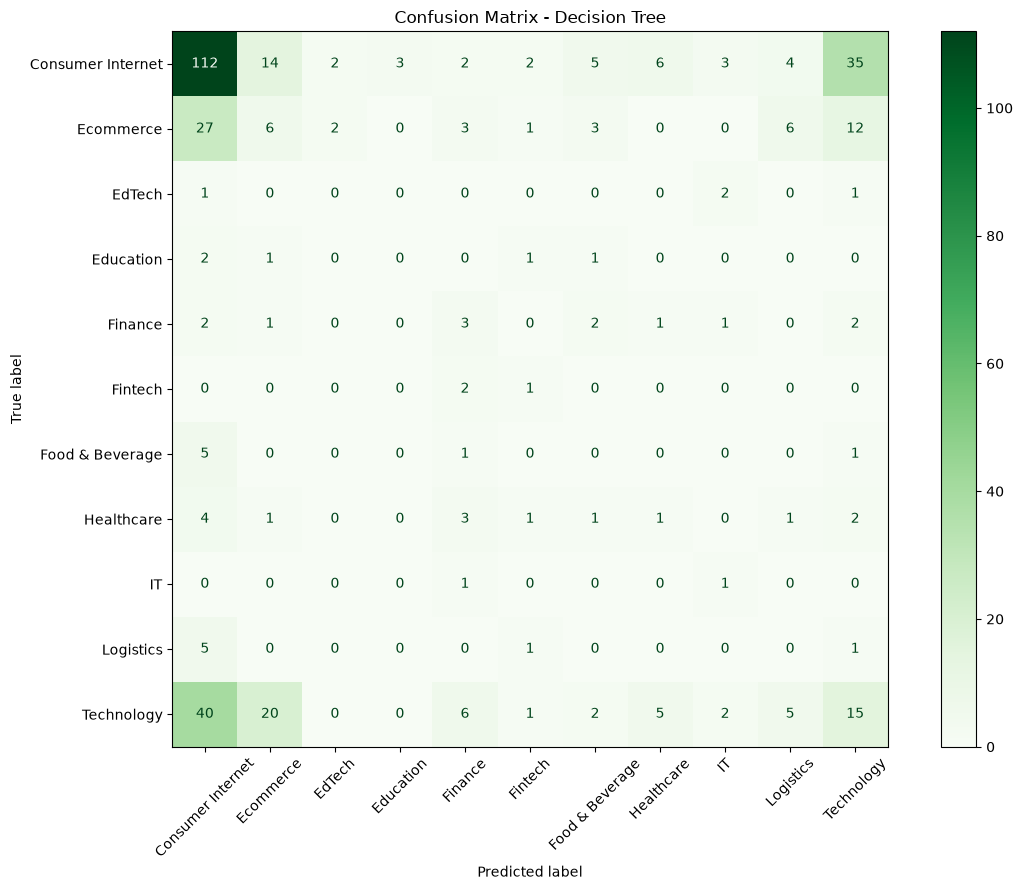

[[112  14   2   3   2   2   5   6   3   4  35]
 [ 27   6   2   0   3   1   3   0   0   6  12]
 [  1   0   0   0   0   0   0   0   2   0   1]
 [  2   1   0   0   0   1   1   0   0   0   0]
 [  2   1   0   0   3   0   2   1   1   0   2]
 [  0   0   0   0   2   1   0   0   0   0   0]
 [  5   0   0   0   1   0   0   0   0   0   1]
 [  4   1   0   0   3   1   1   1   0   1   2]
 [  0   0   0   0   1   0   0   0   1   0   0]
 [  5   0   0   0   0   1   0   0   0   0   1]
 [ 40  20   0   0   6   1   2   5   2   5  15]]

Industry labels:
['Consumer Internet' 'Ecommerce' 'EdTech' 'Education' 'Finance' 'Fintech'
 'Food & Beverage' 'Healthcare' 'IT' 'Logistics' 'Technology']


In [ ]:

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=decision_tree_model.classes_
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=decision_tree_model.classes_
)

fig, ax = plt.subplots(figsize=(12, 9))
disp.plot(
    ax=ax,
    cmap="Greens",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()
print(cm_tree)
print("\nIndustry labels:")
print(decision_tree_model.classes_)

## 11. Model 3: Random Forest Classifier

Random Forest is an ensemble machine learning algorithm that combines multiple Decision Trees to make predictions.

Each tree makes its own prediction, and the final prediction is selected based on the majority vote.

In this project, Random Forest is used to predict the industry sector of a startup using its available information.

In [ ]:
from sklearn.ensemble import RandomForestClassifier


random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
import joblib
from pathlib import Path


project_dir = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

model_path = project_dir / "models" / "random_forest_model.joblib"


joblib.dump(random_forest_model, model_path)

print("Updated Random Forest model saved successfully!")
print("Saved location:", model_path)


print("Model classes:")
print(random_forest_model.classes_)

Updated Random Forest model saved successfully!
Saved location: c:\Users\pavan\Desktop\ds-startup-funding-analysis\models\random_forest_model.joblib
Model classes:
['Consumer Internet' 'Ecommerce' 'EdTech' 'Education' 'Finance' 'Fintech'
 'Food & Beverage' 'Healthcare' 'IT' 'Logistics' 'Technology']


### 11.1 Predictions Using Random Forest

The trained Random Forest model is used to predict the industry sectors of the testing records.

The predicted categories are compared with the actual industry categories to examine the model's predictions.

In [ ]:

y_pred_forest = random_forest_model.predict(X_test)


forest_comparison = pd.DataFrame({
    "Actual Industry": y_test.values,
    "Predicted Industry": y_pred_forest
})

display(forest_comparison.head(10))

,Actual Industry,Predicted Industry
0,Consumer Internet,Consumer Internet
1,Consumer Internet,Consumer Internet
2,Logistics,Consumer Internet
3,Ecommerce,Ecommerce
4,Technology,Consumer Internet
5,Healthcare,Consumer Internet
6,Consumer Internet,Consumer Internet
7,Consumer Internet,Consumer Internet
8,Ecommerce,Consumer Internet
9,Logistics,Consumer Internet


### 11.2 Evaluation of Random Forest

The Random Forest model is evaluated using accuracy, precision, recall and F1-score.

These metrics help measure its classification performance and compare it with the previous models.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)


forest_accuracy = accuracy_score(y_test, y_pred_forest)


forest_macro_f1 = f1_score(
    y_test, y_pred_forest, average="macro"
)

forest_weighted_f1 = f1_score(
    y_test, y_pred_forest, average="weighted"
)

print("Random Forest Accuracy:", forest_accuracy)
print("Macro F1-score:", forest_macro_f1)
print("Weighted F1-score:", forest_weighted_f1)


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_forest,
    zero_division=0
))

Random Forest Accuracy: 0.5
Macro F1-score: 0.1125252547554902
Weighted F1-score: 0.4107708289340703

Classification Report:
                   precision    recall  f1-score   support

Consumer Internet       0.54      0.93      0.68       188
        Ecommerce       0.45      0.08      0.14        60
           EdTech       0.00      0.00      0.00         4
        Education       0.00      0.00      0.00         5
          Finance       1.00      0.08      0.15        12
          Fintech       0.00      0.00      0.00         3
  Food & Beverage       0.00      0.00      0.00         7
       Healthcare       0.00      0.00      0.00        14
               IT       0.00      0.00      0.00         2
        Logistics       0.00      0.00      0.00         7
       Technology       0.39      0.20      0.26        96

         accuracy                           0.50       398
        macro avg       0.22      0.12      0.11       398
     weighted avg       0.45      0.50      0.4

### 11.3 Confusion Matrix for Random Forest

The confusion matrix compares actual industry categories with the categories predicted by the Random Forest model.

It helps identify correct predictions and misclassifications for each industry.

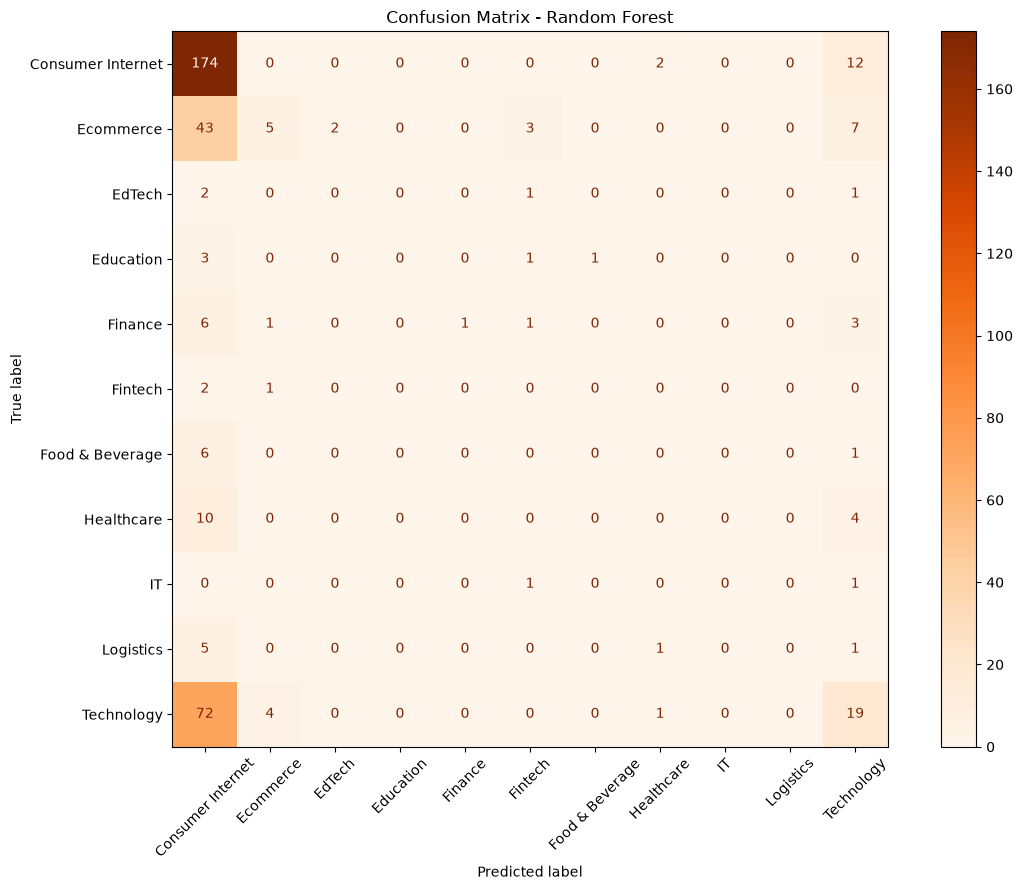

[[174   0   0   0   0   0   0   2   0   0  12]
 [ 43   5   2   0   0   3   0   0   0   0   7]
 [  2   0   0   0   0   1   0   0   0   0   1]
 [  3   0   0   0   0   1   1   0   0   0   0]
 [  6   1   0   0   1   1   0   0   0   0   3]
 [  2   1   0   0   0   0   0   0   0   0   0]
 [  6   0   0   0   0   0   0   0   0   0   1]
 [ 10   0   0   0   0   0   0   0   0   0   4]
 [  0   0   0   0   0   1   0   0   0   0   1]
 [  5   0   0   0   0   0   0   1   0   0   1]
 [ 72   4   0   0   0   0   0   1   0   0  19]]

Industry labels:
['Consumer Internet' 'Ecommerce' 'EdTech' 'Education' 'Finance' 'Fintech'
 'Food & Beverage' 'Healthcare' 'IT' 'Logistics' 'Technology']


In [ ]:

cm_forest = confusion_matrix(
    y_test,
    y_pred_forest,
    labels=random_forest_model.classes_
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_forest,
    display_labels=random_forest_model.classes_
)

fig, ax = plt.subplots(figsize=(12, 9))
disp.plot(
    ax=ax,
    cmap="Oranges",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()
print(cm_forest)
print("\nIndustry labels:")
print(random_forest_model.classes_)

In [ ]:
from sklearn.metrics import roc_auc_score


logistic_prob = logistic_model.predict_proba(X_test)
tree_prob = decision_tree_model.predict_proba(X_test)
forest_prob = random_forest_model.predict_proba(X_test)

logistic_roc_auc = roc_auc_score(
    y_test, logistic_prob,
    multi_class="ovr",
    average="macro",
    labels=logistic_model.classes_
)

tree_roc_auc = roc_auc_score(
    y_test, tree_prob,
    multi_class="ovr",
    average="macro",
    labels=decision_tree_model.classes_
)

forest_roc_auc = roc_auc_score(
    y_test, forest_prob,
    multi_class="ovr",
    average="macro",
    labels=random_forest_model.classes_
)


print("Logistic Regression ROC-AUC:", logistic_roc_auc)
print("Decision Tree ROC-AUC:", tree_roc_auc)
print("Random Forest ROC-AUC:", forest_roc_auc)

Logistic Regression ROC-AUC: 0.6669313498988173
Decision Tree ROC-AUC: 0.5499381588702309
Random Forest ROC-AUC: 0.6858899144497846


## 12. Model Performance Comparison

The three classification models are compared using accuracy, macro F1-score and weighted F1-score.

This comparison helps identify the model with the best overall classification performance.

In [62]:
from sklearn.metrics import f1_score

print("F1-score imported successfully!")

F1-score imported successfully!


In [ ]:

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        forest_accuracy
    ],
    "Macro F1-Score": [
        f1_score(y_test, y_pred_logistic, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro"),
        f1_score(y_test, y_pred_forest, average="macro")
    ],
    "Weighted F1-Score": [
        f1_score(y_test, y_pred_logistic, average="weighted"),
        f1_score(y_test, y_pred_tree, average="weighted"),
        f1_score(y_test, y_pred_forest, average="weighted")
    ]
})

display(model_comparison.round(3))

,Model,Accuracy,Macro F1-Score,Weighted F1-Score
0,Logistic Regression,0.397,0.169,0.428
1,Decision Tree,0.349,0.136,0.346
2,Random Forest,0.500,0.113,0.411


## Improving Model Features

Additional meaningful features are explored to provide more information to the classification models.

### Examining SubVertical

SubVertical provides more specific information about a startup's business activity and may help the model predict its industry sector.

In [64]:
print("Number of unique subverticals:",
      df["SubVertical_Cleaned"].nunique())

print("\nTop 20 subverticals:")
display(df["SubVertical_Cleaned"].value_counts().head(20))

print("\nMissing values:")
print(df["SubVertical_Cleaned"].isnull().sum())

Number of unique subverticals: 1884

Top 20 subverticals:


SubVertical_Cleaned
Unknown                             936
Online Lending Platform              21
Online Pharmacy                      10
Food Delivery Platform               10
Online Learning Platform              9
Online Lending                        5
Online Marketplace                    5
Education                             5
Non-Banking Financial Company         5
Online Food Delivery Platform         5
Online Education Platform             5
Online Gifting Platform               4
Online Payment Gateway                4
Ecommerce Marketplace                 4
Micro Lending Platform                4
Online Consumer Lending Platform      4
Online Insurance Platform             4
Online Food Delivery                  4
Co-Working Spaces                     4
Data Analytics Platform               4
Name: count, dtype: int64


Missing values:
0


In [ ]:

subvertical_counts = df[
    df["SubVertical_Cleaned"] != "Unknown"
]["SubVertical_Cleaned"].value_counts()

print("Total known SubVertical categories:",
      len(subvertical_counts))

print("\nCategories with at least 5 records:",
      (subvertical_counts >= 5).sum())

print("Categories with at least 10 records:",
      (subvertical_counts >= 10).sum())

print("\nRecords in categories with at least 5 records:",
      subvertical_counts[subvertical_counts >= 5].sum())

Total known SubVertical categories: 1883

Categories with at least 5 records: 10
Categories with at least 10 records: 3

Records in categories with at least 5 records: 80


### SubVertical Analysis – Key Findings

The dataset contains 1,884 unique SubVertical categories, including 936 Unknown values. After excluding Unknown, 1,883 known categories remain.

Only 10 categories contain at least 5 records, and only 3 categories contain at least 10 records. This indicates that most SubVertical categories are very rare.

Therefore, SubVertical is a high-cardinality categorical feature. OneHotEncoder with handle_unknown="ignore" is used during preprocessing to handle these categories without manually combining the original SubVertical values.

### Examining Funding Amount as an Additional Feature

Funding amount may provide useful information for predicting the industry sector.

However, some records have missing funding amounts, and the distribution is highly right-skewed. These issues must be considered before including this feature in the model.



In [66]:
print("Missing funding amounts:",
      df["Amount_Cleaned"].isnull().sum())

print("\nAvailable funding amounts:",
      df["Amount_Cleaned"].notnull().sum())

print("\nFunding amount summary:")
display(df["Amount_Cleaned"].describe())

Missing funding amounts: 978

Available funding amounts: 2066

Funding amount summary:


count    2.066000e+03
mean     1.842792e+07
std      1.213441e+08
min      1.600000e+04
25%      4.712500e+05
50%      1.725000e+06
75%      8.000000e+06
max      3.900000e+09
Name: Amount_Cleaned, dtype: float64

### Preparing Funding Amount

Funding amounts contain missing values and extreme variations.

To prepare this feature:
- Missing values will be filled using the median.
- A logarithmic transformation will reduce the effect of extremely large funding amounts.
- The preprocessing steps will be fitted using training data only.

In [68]:
amount_by_industry = (
    model_df.groupby("Industry_Grouped")["Amount_Cleaned"]
    .agg(["count", "median", "mean"])
    .sort_values("count", ascending=False)
)

display(amount_by_industry)

,count,median,mean
Industry_Grouped,,,
Consumer Internet,590,1000000.0,1.060014e+07
Technology,310,1500000.0,7.192606e+06
Ecommerce,205,3000000.0,4.029627e+07
Finance,57,6240000.0,3.458663e+07
Healthcare,45,3000000.0,9.293733e+06
Food & Beverage,25,2000000.0,1.474205e+07
Logistics,23,6000000.0,1.055848e+07
Education,19,1500000.0,1.584963e+07
EdTech,18,886250.0,1.074978e+07
